# PROJECT - BUILDING COMPOSITE FLOOD VULNERABLITY INDEX - USING PCA

## -CC25MTECH11002

In [2]:
import pandas as pd
import numpy as np

# LOADING EXCEL WITH DATASET
## I HAVE ATTACHED THE EXCEL ALONG WITH NOTEBOOK SUBMISSION

In [3]:
fviexcel = r"E:\SEM 1 WORKS\CC ANALYSIS AND METHOD\fvi project\FVI INDICATORS.xlsx"
indicators = pd.read_excel(fviexcel)

# INDICATORS

In [4]:
x = indicators[['population density', 'mean slope (degrees)', 'Normal rainfall SW Monsoon (mm)', 'percentage katcha houses', 'percentage agriculture dependent population', 'number of primary healthcare centres', 'per capita GDDP']]

# PERFORMING PCA ON ORIGINAL INDICATORS

In [5]:
from statsmodels.multivariate.pca import PCA
pca = PCA(x, ncomp=None, standardize=True)

In [6]:
pc = pca.scores

print(pc)

      comp_0    comp_1    comp_2    comp_3    comp_4    comp_5    comp_6
0  -0.297634  0.326733 -0.425216 -0.064223 -0.089170  0.050344 -0.509109
1  -0.239400  0.293488  0.128724  0.187803  0.238052  0.255353  0.184687
2   0.496526  0.082196 -0.006451  0.540679  0.353417 -0.165029 -0.075518
3   0.029193  0.063276  0.384394 -0.192240 -0.220598  0.129364  0.127539
4   0.217378  0.524665 -0.048619 -0.227450 -0.076885  0.230929  0.416483
5  -0.197046 -0.186327 -0.216103 -0.262370  0.104347  0.044726  0.042400
6  -0.056644 -0.216218  0.202986 -0.172657  0.127882 -0.093577 -0.417227
7  -0.113597  0.276102  0.307130  0.154296 -0.052090 -0.578057 -0.105566
8  -0.100005 -0.340622  0.311490  0.084808 -0.471005 -0.110667  0.180825
9   0.105652 -0.376406 -0.134123  0.394240 -0.081307  0.500510 -0.031240
10  0.055905 -0.282031  0.054655 -0.412582  0.611348 -0.083471  0.164733
11 -0.330743 -0.149751 -0.474054  0.205236 -0.074705 -0.336713  0.420302
12 -0.157760  0.034820  0.206489  0.047189 -0.02656

In [7]:
var = pca.rsquare
print(var)

ncomp
0    0.000000
1    0.583791
2    0.764569
3    0.842867
4    0.914904
5    0.973446
6    0.992166
7    1.000000
Name: rsquare, dtype: float64


In [8]:
q = pca.eigenvals

print(q)

0    57.211494
1    17.716294
2     7.673183
3     7.059586
4     5.737135
5     1.834550
6     0.767757
Name: eigenvals, dtype: float64


In [9]:
s = pca.eigenvecs
print(s)

   eigenvec_0  eigenvec_1  eigenvec_2  eigenvec_3  eigenvec_4  eigenvec_5  \
0   -0.440483    0.143006   -0.154122    0.105827   -0.502350   -0.646280   
1    0.415414   -0.231426    0.197314    0.487254    0.291049   -0.612732   
2    0.288079    0.516567    0.732428   -0.015930   -0.253046    0.033867   
3    0.426458    0.123755   -0.312657    0.082544   -0.631707    0.078093   
4    0.452145   -0.063246   -0.376230    0.304337   -0.073326    0.189817   
5   -0.375781   -0.266810    0.271963    0.700993   -0.238032    0.400566   
6   -0.151342    0.754087   -0.295966    0.400382    0.371232    0.056148   

   eigenvec_6  
0   -0.283792  
1    0.193325  
2   -0.219739  
3    0.541386  
4   -0.718323  
5    0.071657  
6    0.139935  


In [10]:
l = pca.loadings
print(l)

                                               comp_0    comp_1    comp_2  \
population density                          -0.440483  0.143006 -0.154122   
mean slope (degrees)                         0.415414 -0.231426  0.197314   
Normal rainfall SW Monsoon (mm)              0.288079  0.516567  0.732428   
percentage katcha houses                     0.426458  0.123755 -0.312657   
percentage agriculture dependent population  0.452145 -0.063246 -0.376230   
number of primary healthcare centres        -0.375781 -0.266810  0.271963   
per capita GDDP                             -0.151342  0.754087 -0.295966   

                                               comp_3    comp_4    comp_5  \
population density                           0.105827 -0.502350 -0.646280   
mean slope (degrees)                         0.487254  0.291049 -0.612732   
Normal rainfall SW Monsoon (mm)             -0.015930 -0.253046  0.033867   
percentage katcha houses                     0.082544 -0.631707  0.078093  

# ORIGINAL INDICATOR WEIGHT DETERMINATION

In [11]:
weigenvecs = l.abs() * (q.values)
print(weigenvecs)

                                                comp_0     comp_1    comp_2  \
population density                           25.200691   2.533541  1.182608   
mean slope (degrees)                         23.766439   4.100012  1.514026   
Normal rainfall SW Monsoon (mm)              16.481405   9.151658  5.620053   
percentage katcha houses                     24.398292   2.192479  2.399071   
percentage agriculture dependent population  25.867889   1.120477  2.886882   
number of primary healthcare centres         21.498986   4.726878  2.086821   
per capita GDDP                               8.658477  13.359621  2.271001   

                                               comp_3    comp_4    comp_5  \
population density                           0.747093  2.882051  1.185633   
mean slope (degrees)                         3.439808  1.669786  1.124088   
Normal rainfall SW Monsoon (mm)              0.112459  1.451760  0.062130   
percentage katcha houses                     0.582726  3.62

In [12]:
we = weigenvecs.sum('columns')
print(we)

population density                             33.949500
mean slope (degrees)                           35.762586
Normal rainfall SW Monsoon (mm)                33.048172
percentage katcha houses                       33.755674
percentage agriculture dependent population    33.344150
number of primary healthcare centres           35.416898
per capita GDDP                                29.455880
dtype: float64


In [13]:
tot =we.sum('rows')
print(tot)

234.73285924539272


# #RESULT: ORIGNAL INDICATORS WEIGHT

In [14]:
weight = we*100/tot
print(weight)

population density                             14.463037
mean slope (degrees)                           15.235441
Normal rainfall SW Monsoon (mm)                14.079056
percentage katcha houses                       14.380464
percentage agriculture dependent population    14.205148
number of primary healthcare centres           15.088172
per capita GDDP                                12.548682
dtype: float64


# COMPOSITE FVI USING VARIANCE AS WEIGHT

In [15]:
fvi = pc @(q.values)

print(fvi)

0    -15.765831
1     -4.207401
2     35.297558
3      3.453215
4     20.055195
5    -17.371476
6     -6.490934
7      0.398037
8    -11.533594
9      1.557789
10    -0.810719
11   -24.487594
12    -6.300771
13    26.206528
dtype: float64


In [16]:
fvi_df = pd.DataFrame()
y = indicators['district']
fvi_df['district'] = y.values
fvi_df['fvi'] = fvi.values

fvi_df['FVI_Normalized'] = (fvi_df['fvi'] - fvi_df['fvi'].min()) / (fvi_df['fvi'].max() - fvi_df['fvi'].min())

print("Final Normalized FVI Ranks")
print(fvi_df)

Final Normalized FVI Ranks
              district        fvi  FVI_Normalized
0            Alappuzha -15.765831        0.145885
1            Ernakulam  -4.207401        0.339218
2               Idukki  35.297558        1.000000
3               Kannur   3.453215        0.467354
4            Kasaragod  20.055195        0.745048
5               Kollam -17.371476        0.119028
6             Kottayam  -6.490934        0.301022
7            Kozhikode   0.398037        0.416251
8           Malappuram -11.533594        0.216676
9             Palakkad   1.557789        0.435650
10      Pathanamthitta  -0.810719        0.396033
11  Thiruvananthapuram -24.487594        0.000000
12            Thrissur  -6.300771        0.304203
13             Wayanad  26.206528        0.847938


# #PLOTING COMPOSITE FVI RESULT

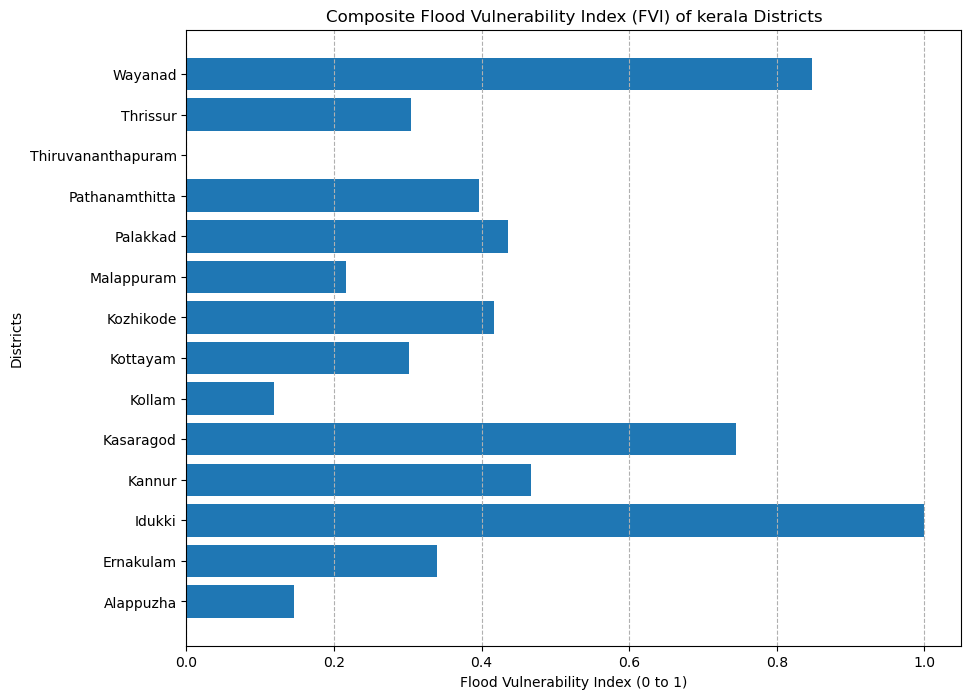

In [17]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 8))
plt.barh(
    fvi_df['district'], 
    fvi_df['FVI_Normalized']
)

plt.xlabel('Flood Vulnerability Index (0 to 1)')
plt.ylabel('Districts')
plt.title('Composite Flood Vulnerability Index (FVI) of kerala Districts')
plt.grid(axis='x', linestyle='--') 

plt.show()

# FVI WITH ORIGINAL INDICATORS WITH DETERMINED WEIGHTS

In [43]:
z = (x - x.mean()) / x.std()
# Define the list of indicators that are "good"
negative_indicators = [
    'per capita GDDP', 
    'number of primary healthcare centres'
]


weight[negative_indicators] = weight[negative_indicators] * -1
print(weight)


population density                             14.463037
mean slope (degrees)                           15.235441
Normal rainfall SW Monsoon (mm)                14.079056
percentage katcha houses                       14.380464
percentage agriculture dependent population    14.205148
number of primary healthcare centres          -15.088172
per capita GDDP                               -12.548682
dtype: float64


In [44]:
wfvi= z @ (weight.values)

print(wfvi)

0     -45.129462
1     -59.169512
2      76.691844
3      11.372744
4      35.013328
5     -41.010831
6      -9.263221
7       0.498253
8       1.804113
9       4.729317
10    -13.877686
11    -51.811420
12    -32.260827
13    122.413360
dtype: float64


In [53]:
wfvi_df = pd.DataFrame()
y = indicators['district']
wfvi_df['district'] = y.values
wfvi_df['wfvi'] = wfvi.values

wfvi_df['wFVI_Normalized'] = (wfvi_df['wfvi'] - wfvi_df['wfvi'].min()) / (wfvi_df['wfvi'].max() - wfvi_df['wfvi'].min())
wfvi_df = wfvi_df.sort_values(by='wFVI_Normalized', ascending=False)
fvi_df = fvi_df.sort_values(by='FVI_Normalized', ascending=False)
print("Final Normalized wFVI Ranks")
print(wfvi_df)
print(fvi_df)

Final Normalized wFVI Ranks
              district        wfvi  wFVI_Normalized
13             Wayanad  122.413360         1.000000
2               Idukki   76.691844         0.748206
4            Kasaragod   35.013328         0.518677
3               Kannur   11.372744         0.388485
9             Palakkad    4.729317         0.351899
8           Malappuram    1.804113         0.335790
7            Kozhikode    0.498253         0.328598
6             Kottayam   -9.263221         0.274840
10      Pathanamthitta  -13.877686         0.249428
12            Thrissur  -32.260827         0.148190
5               Kollam  -41.010831         0.100002
0            Alappuzha  -45.129462         0.077320
11  Thiruvananthapuram  -51.811420         0.040522
1            Ernakulam  -59.169512         0.000000
              district        fvi  FVI_Normalized
2               Idukki  35.297558        1.000000
13             Wayanad  26.206528        0.847938
4            Kasaragod  20.055195        0

# #PLOTING ORIGINAL INDICATORS FVI RESULT

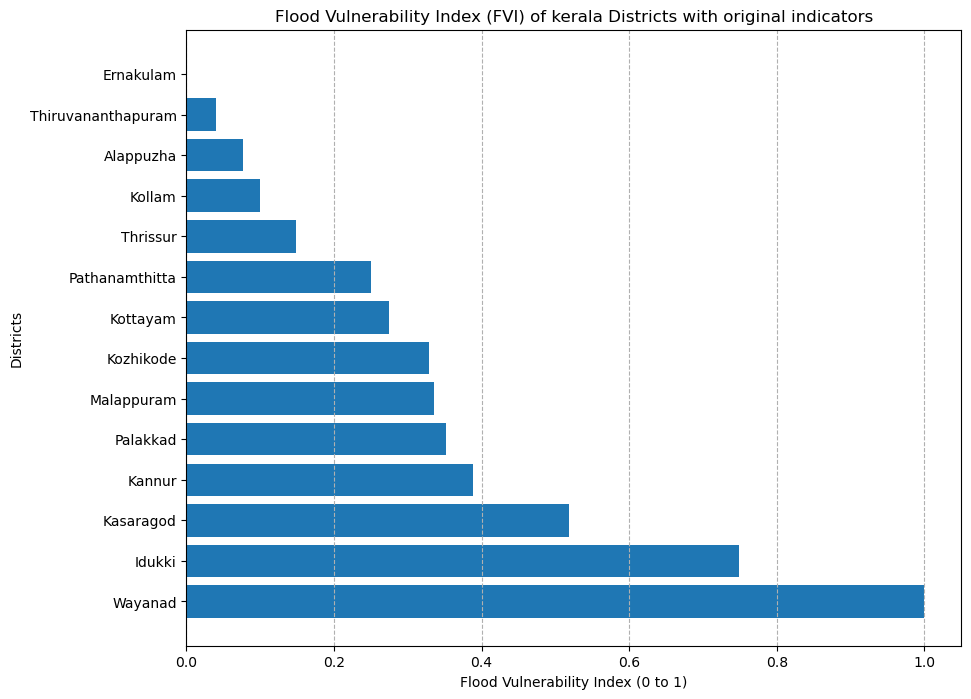

In [51]:
plt.figure(figsize=(10, 8))
plt.barh(
    wfvi_df['district'], 
    wfvi_df['wFVI_Normalized']
)

plt.xlabel('Flood Vulnerability Index (0 to 1)')
plt.ylabel('Districts')
plt.title('Flood Vulnerability Index (FVI) of kerala Districts with original indicators')
plt.grid(axis='x', linestyle='--') 

plt.show()

# COMPARING COMPOSITE FVI AND ORIGINAL INDICATOR FVI

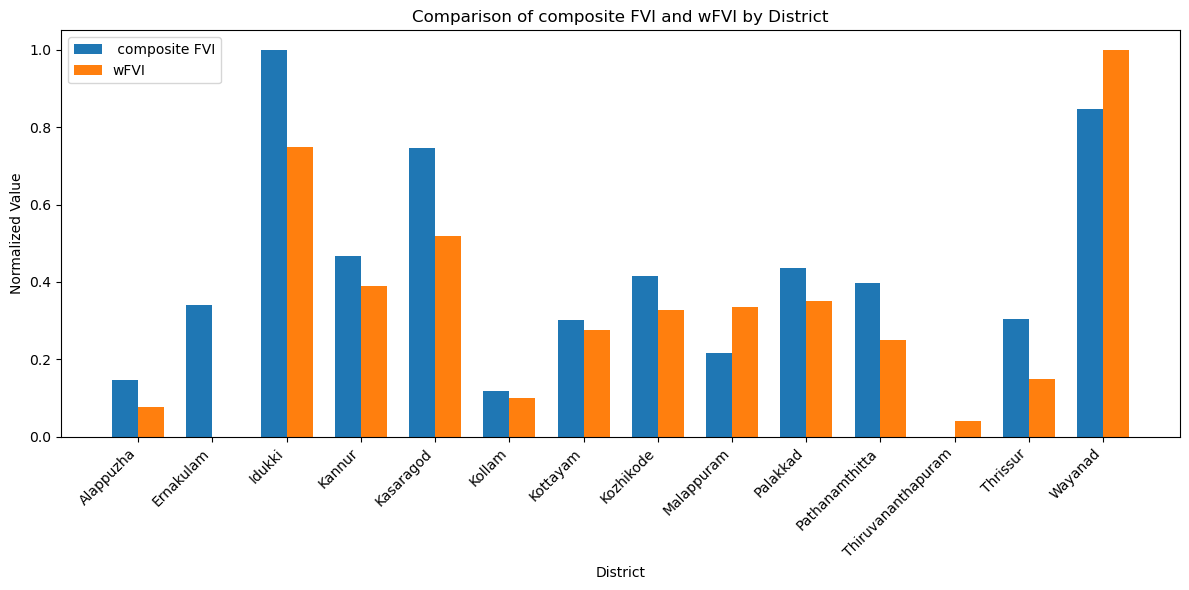

In [52]:
import pandas as pd
import matplotlib.pyplot as plt


merged_df = pd.merge(fvi_df[['district', 'FVI_Normalized']],
                     wfvi_df[['district', 'wFVI_Normalized']],
                     on='district')

merged_df = merged_df.sort_values('district')


plt.figure(figsize=(12,6))
x = range(len(merged_df))
width = 0.35

plt.bar([i - width/2 for i in x], merged_df['FVI_Normalized'], width=width, label=' composite FVI')
plt.bar([i + width/2 for i in x], merged_df['wFVI_Normalized'], width=width, label='wFVI')

plt.xticks(x, merged_df['district'], rotation=45, ha='right')
plt.xlabel('District')
plt.ylabel('Normalized Value')
plt.title('Comparison of composite FVI and wFVI by District')
plt.legend()
plt.tight_layout()
plt.show()


# FAILED MAP PLOTING - MERGING ISSUE WITH DISTRICT SHAPEFILE NAMES

In [21]:
import pandas as pd
import geopandas as gpd
map_df = gpd.read_file(r"C:\Users\Niteshkumar\Downloads\Kerala_districts.geojson")

print(map_df)
    




D:\New folder\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


                   id               @id addr:street admin_level     alt_name  \
0    relation/1818784  relation/1818784        None           5   Trivandrum   
1    relation/1819274  relation/1819274        None           5         None   
2    relation/1819321  relation/1819321        None           5         None   
3    relation/2018154  relation/2018154        None           5         None   
4    relation/2018176  relation/2018176        None           5         None   
..                ...               ...         ...         ...          ...   
840   node/8779650703   node/8779650703        None        None  Kanhirakode   
841   node/7514559782   node/7514559782        None        None         None   
842   node/5215512955   node/5215512955        None        None         None   
843   node/5211742569   node/5211742569        None        None         None   
844   node/5217707521   node/5217707521        None        None         None   

    alt_name:pt alt_name:uk        boun

In [22]:
merged_map = map_df.merge(fvi_df, left_on='alt_name', right_on='district')

print(merged_map.head())

Empty GeoDataFrame
Columns: [id, @id, addr:street, admin_level, alt_name, alt_name:pt, alt_name:uk, boundary, bridge:support, capital, description, ele, gns:dsg, gns:uni, is_capital, is_in, is_in:country, is_in:country_code, is_in:district, is_in:state, isolation, name, name:ar, name:cs, name:en, name:eo, name:he, name:hi, name:ja, name:kn, name:lt, name:mg, name:ml, name:new, name:pa, name:pt, name:ru, name:sa, name:sr, name:ta, name:te, name:tr, name:uk, name:ur, name:vi, name:war, name:zh, natural, note, old_name, place, place:cca, population, postal_code, power, prominence, source, type, waterway, website, wikidata, wikipedia, wikipedia:de, @timestamp, @version, @changeset, @user, @uid, @relations, geometry, district, fvi, FVI_Normalized]
Index: []

[0 rows x 73 columns]


# THE END
# ##########THANKYOU##########